# Lost in the Middle — Laboratório Experimental
### Aula 02 · Janela de contexto, confiabilidade e avaliação controlada

**MATERIAL DO ESTUDANTE — Experimento de contexto longo com LLMs**

**Questão de investigação:** *quando uma informação está dentro da janela de contexto, o modelo consegue utilizá-la com a mesma confiabilidade independentemente da posição em que ela aparece?*

Neste laboratório, você vai preparar documentos técnicos fictícios, posicionar a mesma evidência em diferentes lugares do contexto, inspecionar os prompts e, se habilitar a API, **executar o experimento com um modelo real**. O objetivo é investigar uma hipótese, não obter um resultado predeterminado.

**Ao final, você deverá conseguir:**

- Distinguir capacidade nominal da janela e qualidade observada de recuperação de informações.
- Explicar o fenômeno *Lost in the Middle* e os conceitos de *primacy* e *recency*.
- Controlar a posição de uma evidência mantendo os demais fatores tão constantes quanto possível.
- Avaliar respostas, fontes utilizadas, tokens e latência.
- Formular conclusões proporcionais às observações e às limitações do experimento.

**Duração de referência:** 45–60 minutos, com extensões opcionais.

**Base científica:** Liu et al. (2024), [*Lost in the Middle: How Language Models Use Long Contexts*](https://aclanthology.org/2024.tacl-1.9/). Este notebook adapta a **metodologia**, mas utiliza dados sintéticos e não reproduz os resultados quantitativos do artigo. [Repositório dos autores](https://github.com/nelson-liu/lost-in-the-middle).


## 1. O problema: caber na janela significa utilizar corretamente?

Na aula anterior, vimos que a janela de contexto estabelece quanto conteúdo um modelo pode receber e processar, dentro dos limites de sua API. Entretanto, **receber uma evidência não garante utilizá-la corretamente na resposta**.

Considere um assistente que recebe vários documentos sobre serviços de software. Um deles contém a resposta exata à pergunta. Mesmo que nenhum documento seja truncado, o modelo pode ou não localizar e utilizar esse trecho corretamente.

**Conceitos essenciais:**

- **Contexto nominal:** capacidade máxima de tokens admitida pelo modelo ou serviço, sujeita às regras de entrada e saída.
- **Uso efetivo do contexto:** qualidade observada ao recuperar e usar informações em uma tarefa específica. Não constitui um único limite universal do modelo.
- **Lost in the Middle:** padrão identificado em determinadas avaliações no qual a utilização de uma informação pode ser inferior quando ela aparece no meio do contexto, em comparação com as extremidades.
- **Primacy e recency:** efeitos associados à maior influência de informações próximas, respectivamente, do início e do final de uma sequência, dependendo da tarefa e do modelo.

**Questão para reflexão:** se os documentos enviados forem os mesmos, uma mudança de ordem poderá alterar a resposta? Que evidência seria necessária para testar essa hipótese?


### Visual 1 — Hipótese que será investigada

A figura a seguir mostra uma **curva em U conceitual** inspirada no padrão descrito na literatura. **Os pontos não são medições deste notebook nem dados extraídos do artigo.** Os gráficos de resultados reais só serão produzidos após executar o LLM.

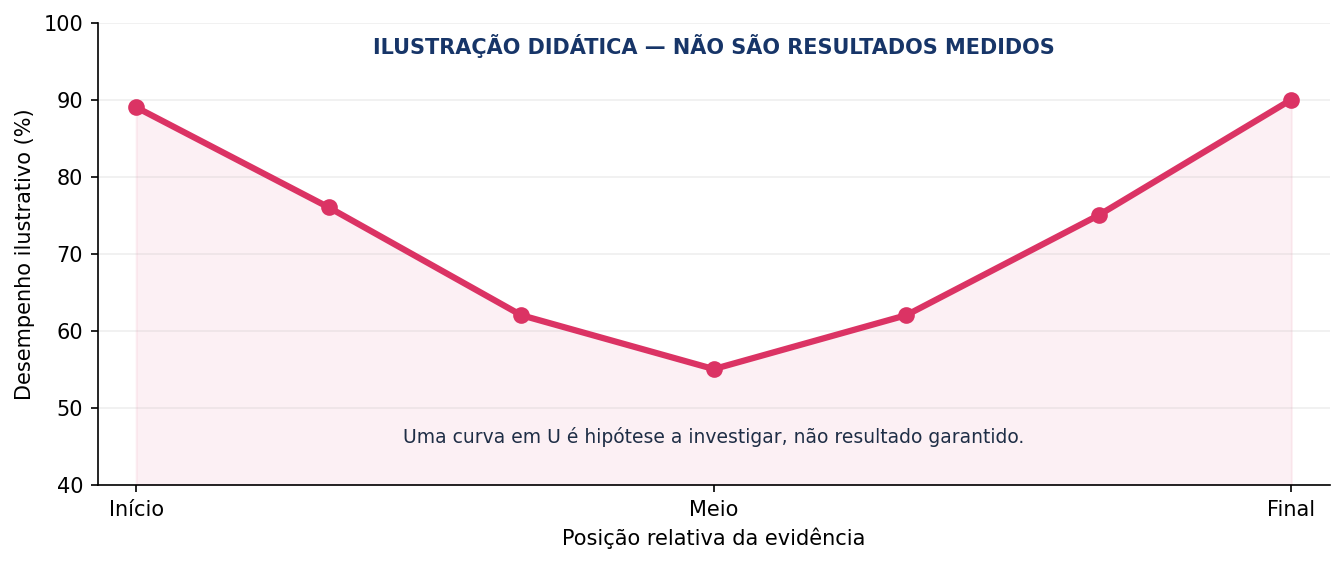

**Observe:** um padrão descrito em um estudo não garante que você observará a mesma curva com outro modelo, outro conjunto documental ou uma única pergunta.


## 2. Fundamento científico e adaptação do experimento

No trabalho de Liu et al., os autores avaliaram **perguntas com múltiplos documentos** e recuperação de informações no formato **chave–valor**. Entre os fatores investigados estavam a **posição da informação relevante** e o **comprimento do contexto**. Em diferentes condições, foi observado desempenho inferior quando a informação estava próxima do meio.

**Como adaptaremos o procedimento neste laboratório:**

1. Definir uma pergunta técnica com resposta verificável.
2. Preparar uma coleção de documentos fictícios plausíveis, contendo uma única fonte relevante para a configuração solicitada.
3. Enviar sempre **a mesma pergunta, as mesmas instruções e o mesmo conjunto de documentos**.
4. Mudar a posição do documento relevante para **início, meio e final**, sem acrescentar ou excluir fontes.
5. Registrar respostas produzidas pelo modelo, identificação da fonte, tokens e latência.
6. Analisar se as observações sustentam alguma conclusão sobre efeito de posição **nas condições testadas**.

**O que é reproduzido:** a lógica de um teste controlado de posição de evidência em *multi-document QA*.

**O que não é reproduzido:** o corpus *Natural Questions*, a seleção exata de modelos, as escalas e os resultados numéricos do estudo original. Os documentos aqui são sintéticos e tratam de operações de APIs.

**Desafio metodológico:** explique por que acrescentar documentos diferentes a cada teste impediria atribuir uma eventual mudança da resposta somente à posição da evidência.


### Visual 2 — Mesmos documentos, posições diferentes

Cada bloco representa um documento. O bloco verde identifica **a mesma fonte com a evidência correta**; os outros blocos são distratores que não devem mudar entre as condições.

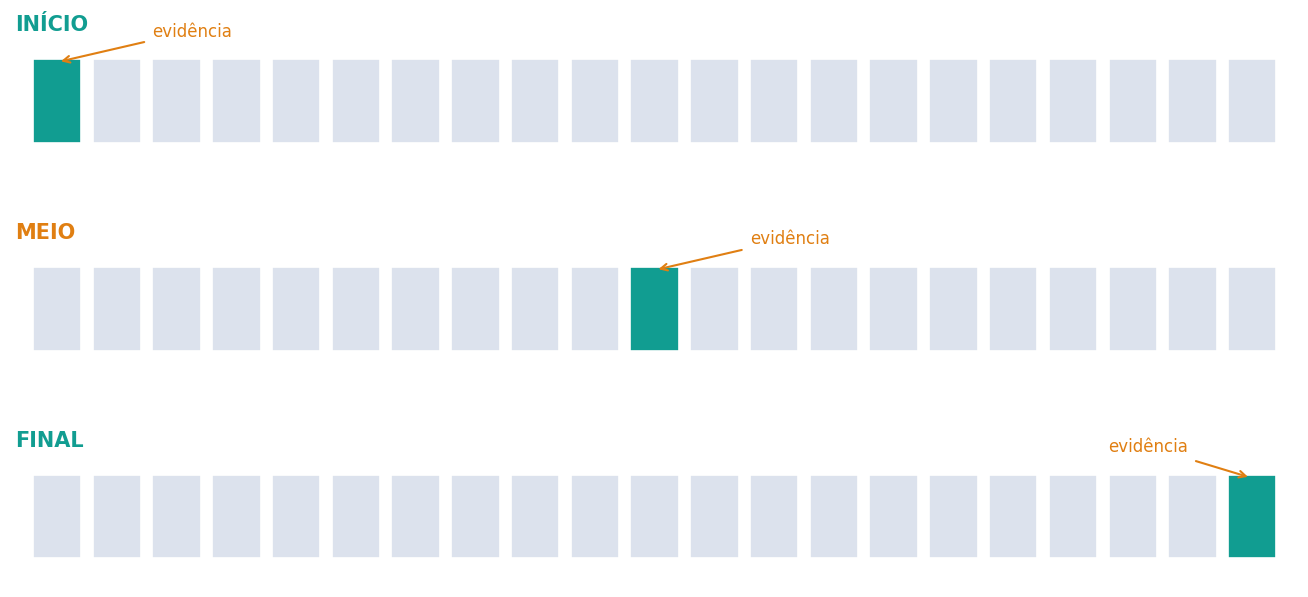

A figura representa **como montaremos as entradas**. Ainda não há nenhuma resposta de modelo associada a esses arranjos.


## 3. Prepare o ambiente de execução

O notebook começa com a **geração local de documentos e a inspeção dos prompts**. Essa etapa não precisa de chave de API nem produz cobranças de inferência. As chamadas reais são habilitadas explicitamente depois.

**No terminal do VS Code, com seu ambiente virtual ativo:**

```bash
python -m pip install numpy pandas matplotlib openai python-dotenv ipykernel
```

**Para executar o modelo real:** configure `OPENAI_API_KEY` como variável de ambiente ou em um arquivo `.env` na **mesma pasta do notebook**. Não inclua a chave no código nem versione o `.env`.

**Modelo e capacidade:** o identificador do modelo é editável na célula de configuração. O exemplo inicial usa `gpt-5-mini`. Verifique disponibilidade, limite de contexto e eventuais custos no provedor antes de aumentar a escala.

**Sua tarefa nesta etapa:** execute a célula de configuração, identifique os parâmetros `MODELO`, `N_DOCUMENTOS`, `PARAGRAFOS_POR_DOCUMENTO`, `REPETICOES` e `EXECUTAR_API` e observe como cada um influencia o experimento.


### Configuração para Gemini (Google AI Studio)

1. Gere uma chave em [Google AI Studio → API keys](https://aistudio.google.com/api-keys).
2. Coloque um arquivo `.env` na pasta do notebook:

```dotenv
LLM_PROVIDER=gemini
GEMINI_API_KEY=cole-a-chave-aqui
GEMINI_MODEL=gemini-3.5-flash-lite
```

3. Instale as dependências no ambiente virtual (`python -m pip install -U openai python-dotenv numpy pandas matplotlib ipykernel`).
4. Para um teste inicial de **3 chamadas**, ajuste `QUANTOS_CASOS = 1` e `REPETICOES = 1` na configuração. Aumente depois conforme a cota gratuita.
5. `EXECUTAR_API = True` inicia chamadas **reais**. Para voltar à OpenAI, mude `LLM_PROVIDER=openai`, configure `OPENAI_API_KEY` e `OPENAI_MODEL` no `.env`.

**Atenção:** os limites gratuitos variam por projeto e modelo. Se aparecer `429 RESOURCE_EXHAUSTED`, examine as cotas no AI Studio. Não publique o arquivo `.env`. Os resultados anteriores foram apagados nesta cópia para evitar misturar medições de modelos diferentes.

A **montagem e a ordem dos documentos, perguntas, distratores, repetições, gráficos e controles** seguem os mesmos experimentos da versão anterior. A única alteração na avaliação é ignorar pontuação final (`43 dias` = `43 dias.`), evitando falsos negativos.


In [1]:
import os, re, json, time, random, unicodedata
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    from dotenv import load_dotenv
    load_dotenv(dotenv_path=Path.cwd() / '.env')
except ImportError:
    print('python-dotenv ausente: usando somente variáveis já definidas no ambiente.')

# ALTERE ESTES PARÂMETROS ANTES DE EXECUTAR AS CHAMADAS REAIS
# Altere o provedor no arquivo .env: gemini ou openai.
PROVEDOR = os.getenv('LLM_PROVIDER', 'gemini').strip().lower()
if PROVEDOR not in {'gemini', 'openai'}:
    raise ValueError('LLM_PROVIDER deve ser gemini ou openai')
MODELO = (os.getenv('GEMINI_MODEL', 'gemini-3.5-flash-lite') if PROVEDOR == 'gemini'
          else os.getenv('OPENAI_MODEL', 'gpt-5-mini'))
N_DOCUMENTOS = 60                 # Primeira demonstração: 24; desafio: 60 ou 90
PARAGRAFOS_POR_DOCUMENTO = 7     # Aumente para criar contextos mais longos
SEMENTE = 42
MAX_OUTPUT_TOKENS = 1200       # Inclui eventuais tokens de raciocínio interno
EXECUTAR_API = True              # Mude para True SOMENTE quando decidir consumir a API
REPETICOES = 3                    # Em avaliação mais séria, use >= 3
QUANTOS_CASOS = 3                # 1 = demonstração; 3 = avaliação com 3 perguntas

print('Provedor:',PROVEDOR,'| Modelo configurado:', MODELO)
print('Nº documentos:', N_DOCUMENTOS, '| Parágrafos/documento:', PARAGRAFOS_POR_DOCUMENTO)
print('Chamadas piloto:', QUANTOS_CASOS * REPETICOES * 3, '| API habilitada?', EXECUTAR_API)

Provedor: gemini | Modelo configurado: gemini-3.5-flash-lite
Nº documentos: 60 | Parágrafos/documento: 7
Chamadas piloto: 27 | API habilitada? True


## 4. Cenário experimental: documentação de serviços

**Cenário fictício:** uma organização possui diversos *runbooks* técnicos de serviços, versões e ambientes. Um assistente precisa localizar a **configuração correta para o serviço, ambiente e versão solicitados**, citando o identificador da fonte utilizada.

O desafio envolve documentos aparentemente semelhantes: versões, ambientes e valores de configuração podem ser diferentes. Recuperar um número qualquer não basta; é preciso verificar **a correspondência com o caso solicitado**.

**Pergunta do primeiro caso:** *Qual é o `read_timeout` do serviço Checkout Orion em produção na versão v2026.4? Informe valor e ID da fonte.*

O notebook contém dados e respostas de referência **sintéticos** para permitir a avaliação automatizada. Essa referência é utilizada apenas para comparar os resultados obtidos; não representa documentação de uma API real.

Há ainda duas perguntas alternativas, sobre retenção de dados e tamanho de lote, para apoiar investigações além de um único caso.

**Observe na próxima célula:** onde são definidos os casos, como os documentos distratores são gerados e quais atributos permitem diferenciar fontes relevantes de fontes parecidas.


In [2]:
CASOS = [
    {'nome': 'Timeout em produção', 'servico': 'Checkout Orion', 'ambiente': 'produção',
     'versao': 'v2026.4', 'campo': 'read_timeout', 'valor': '17 segundos',
     'fonte': 'OPS-227', 'pergunta': 'Qual é o read_timeout do serviço Checkout Orion no ambiente de produção, versão v2026.4?'},
    {'nome': 'Retenção em produção', 'servico': 'Ledger Aurora', 'ambiente': 'produção',
     'versao': 'v2026.4', 'campo': 'retention_days', 'valor': '43 dias',
     'fonte': 'OPS-314', 'pergunta': 'Qual é o retention_days do serviço Ledger Aurora no ambiente de produção, versão v2026.4?'},
    {'nome': 'Lote em produção', 'servico': 'Notify Pulsar', 'ambiente': 'produção',
     'versao': 'v2026.4', 'campo': 'max_batch_size', 'valor': '275 eventos',
     'fonte': 'OPS-502', 'pergunta': 'Qual é o max_batch_size do serviço Notify Pulsar no ambiente de produção, versão v2026.4?'},
]

TEXTO_OPERACIONAL = [
    'O serviço publica logs estruturados com identificadores de correlação, duração e nível de severidade.',
    'Mudanças de configuração exigem registro de versão, responsável técnico e evidência de validação.',
    'A equipe realiza testes de integração antes de promover uma alteração para o ambiente seguinte.',
    'O monitoramento inclui percentual de erros, percentis de latência e filas de processamento.',
    'As rotinas de contingência preservam trilhas de auditoria e estados de execução consistentes.',
    'A revisão periódica valida documentação operacional, alertas e limites de capacidade.',
    'As políticas de acesso são aplicadas antes das consultas a dados sensíveis e registros internos.',
    'Os endpoints são avaliados sob diferentes perfis de tráfego e estratégias de retry.',
    'O time registra incidentes, hipóteses técnicas, investigações e ações de acompanhamento.',
    'Há verificações de integridade para evitar divergências entre registros e eventos publicados.',
    'Os dashboards separam consumo de recursos, qualidade do serviço e tempo de resposta percebido.',
    'A governança de mudanças estabelece fluxo de aprovação para alterações que afetam produção.',
]

def corpo_neutro(i, n_paragrafos, semente):
    rng = random.Random(semente * 10000 + i)
    partes = []
    for p in range(n_paragrafos):
        trechos = rng.sample(TEXTO_OPERACIONAL, 4)
        partes.append(f'Seção operacional {p+1}: ' + ' '.join(trechos))
    return '\n\n'.join(partes)

def criar_documentos(caso, total=24, paragrafos=7, semente=42):
    assert total >= 5
    # Um documento é a evidência correta; os demais incluem versões, ambientes e serviços próximos.
    alvo = {
        'id': caso['fonte'], 'relevante': True,
        'texto': (f'ID: {caso["fonte"]}\n'
                  f'Título: Runbook de configuração — {caso["servico"]}\n'
                  f'Serviço: {caso["servico"]}\nAmbiente: {caso["ambiente"]}\n'
                  f'Versão: {caso["versao"]}\nStatus: VIGENTE\n'
                  f'Configuração {caso["campo"]}: {caso["valor"]}.\n'
                  f'Este é o valor de referência validado para a combinação acima.\n\n'
                  + corpo_neutro(999, paragrafos, semente)),
    }
    alternativas_servico = ['Checkout Orion', 'Ledger Aurora', 'Notify Pulsar',
                            'Gateway Sideral', 'Queue Nebula', 'Audit Celeste']
    ambientes = ['produção', 'homologação', 'desenvolvimento']
    versoes = ['v2026.4', 'v2026.2', 'v2025.11']
    campos = ['read_timeout', 'retention_days', 'max_batch_size']
    unidades = {'read_timeout': 'segundos', 'retention_days': 'dias', 'max_batch_size': 'eventos'}
    numeros = [5, 8, 10, 12, 15, 20, 24, 30, 35, 55, 64, 90, 128, 256, 500, 750]
    rng = random.Random(semente)
    distractores=[]
    for i in range(total-1):
        # Distratores deliberadamente parecidos, sem duplicar a combinação exata do alvo.
        if i % 3 == 0:
            servico,ambiente,versao=caso['servico'],'homologação',caso['versao']
        elif i % 3 == 1:
            servico,ambiente,versao=caso['servico'],'produção','v2025.11'
        else:
            servico=rng.choice([s for s in alternativas_servico if s != caso['servico']])
            ambiente,versao='produção',caso['versao']
        campo = caso['campo'] if i % 5 != 4 else rng.choice([x for x in campos if x != caso['campo']])
        valor = f'{numeros[i % len(numeros)]} {unidades[campo]}'
        idx = f'OPS-{700 + i:03d}'
        texto=(f'ID: {idx}\nTítulo: Runbook de configuração — {servico}\n'
               f'Serviço: {servico}\nAmbiente: {ambiente}\nVersão: {versao}\n'
               f'Status: {"HISTÓRICO" if versao != caso["versao"] else "VIGENTE"}\n'
               f'Configuração {campo}: {valor}.\n'
               f'Este documento se aplica somente ao serviço, ambiente e versão acima.\n\n'
               + corpo_neutro(i, paragrafos, semente))
        distractores.append({'id':idx, 'relevante':False, 'texto':texto})
    return [alvo]+distractores

caso_piloto = CASOS[0]
docs_base = criar_documentos(caso_piloto, N_DOCUMENTOS, PARAGRAFOS_POR_DOCUMENTO, SEMENTE)
print('Total de documentos:', len(docs_base))
print('Resposta esperada:', caso_piloto['valor'], '| fonte:', caso_piloto['fonte'])
print('1º distractor (trecho):\n', docs_base[1]['texto'][:260], '...')

Total de documentos: 60
Resposta esperada: 17 segundos | fonte: OPS-227
1º distractor (trecho):
 ID: OPS-700
Título: Runbook de configuração — Checkout Orion
Serviço: Checkout Orion
Ambiente: homologação
Versão: v2026.4
Status: VIGENTE
Configuração read_timeout: 5 segundos.
Este documento se aplica somente ao serviço, ambiente e versão acima.

Seção opera ...


## 5. Desenho experimental: uma variável principal

Os três testes serão construídos a partir do **mesmo conjunto documental**. O documento relevante troca de lugar com o documento da posição-alvo; nenhum arquivo é incluído nem removido. Assim, nossa intervenção principal é a **ordem** do conteúdo.

| Elemento | Como será tratado |
|:--|:--|
| **Variável independente** | Posição da fonte relevante: início, meio ou final. |
| **Condições controladas** | Mesma pergunta, documentos, instruções, modelo e configuração de geração. |
| **Variáveis observadas** | Resposta correta, fonte citada, tokens de entrada/saída e latência. |
| **Isolamento** | Cada condição usa uma chamada independente, sem reutilizar a resposta anterior. |

**Atividade de análise:** antes de executar a inferência, verifique se o documento correto realmente aparece em três posições distintas. Compare os IDs de todos os documentos entre as condições.

**Pergunta para registrar:** quais verificações você faria se obtivesse um erro exclusivamente na posição central? Evite atribuir a causa antes de inspecionar as entradas e os resultados.


In [3]:
POSICOES = ['Início', 'Meio', 'Final']

def ordenar_documentos(docs, posicao):
    ordenados = [dict(d) for d in docs]
    alvo = next(i for i,d in enumerate(ordenados) if d['relevante'])
    destinos = {'Início':0,'Meio':len(ordenados)//2,'Final':len(ordenados)-1}
    destino = destinos[posicao]
    ordenados[alvo],ordenados[destino] = ordenados[destino],ordenados[alvo]
    return ordenados

INSTRUCOES = """Você é um assistente técnico que responde exclusivamente a partir dos documentos fornecidos.
Identifique serviço, ambiente, versão e configuração solicitada. Se a evidência exata não estiver
presente, responda NAO_ENCONTRADO. Não use memória externa nem suponha valores.
Responda apenas JSON válido, sem Markdown, no formato:
{"resposta":"valor com unidade ou NAO_ENCONTRADO","fonte":"ID-DA-FONTE ou null"}.
Cite o identificador do documento que sustenta o valor. Não cite documentos de outro ambiente/versão."""

def montar_entrada(caso, docs):
    blocos='\n\n'.join(f'----- DOCUMENTO {i+1} -----\n{d["texto"]}' for i,d in enumerate(docs))
    return (f'DOCUMENTOS DISPONÍVEIS ({len(docs)}):\n\n{blocos}\n\n'
            f'PERGUNTA DO USUÁRIO: {caso["pergunta"]}\n'
            f'Retorne resposta objetiva com valor, unidade e ID da fonte.')

arranjos = {pos:ordenar_documentos(docs_base,pos) for pos in POSICOES}
prompts = {pos:montar_entrada(caso_piloto,arranjos[pos]) for pos in POSICOES}
ids_base = Counter(d['id'] for d in docs_base)
assert all(Counter(d['id'] for d in seq) == ids_base for seq in arranjos.values())
assert len({len(p) for p in prompts.values()}) == 1, 'Os contextos devem ter mesmo tamanho em caracteres'
assert all(sum(d['relevante'] for d in seq)==1 for seq in arranjos.values())

resumo=[]
for pos,seq in arranjos.items():
    indice=next(i for i,d in enumerate(seq) if d['relevante'])
    resumo.append({'Condição':pos,'Posição do alvo':f'{indice+1}/{len(seq)}',
                   '% da lista':round(100*indice/(len(seq)-1),1),
                   'Documentos':len(seq),'Caracteres do prompt':len(prompts[pos]),
                   'Tokens aproximados*':round(len(prompts[pos])/4)})

controle_df=pd.DataFrame(resumo)
display(controle_df)
print('* Estimativa grosseira (caracteres/4), não tokenização real.')

,Condição,Posição do alvo,% da lista,Documentos,Caracteres do prompt,Tokens aproximados*
0,Início,1/60,0.0,60,182723,45681
1,Meio,31/60,50.8,60,182723,45681
2,Final,60/60,100.0,60,182723,45681


* Estimativa grosseira (caracteres/4), não tokenização real.


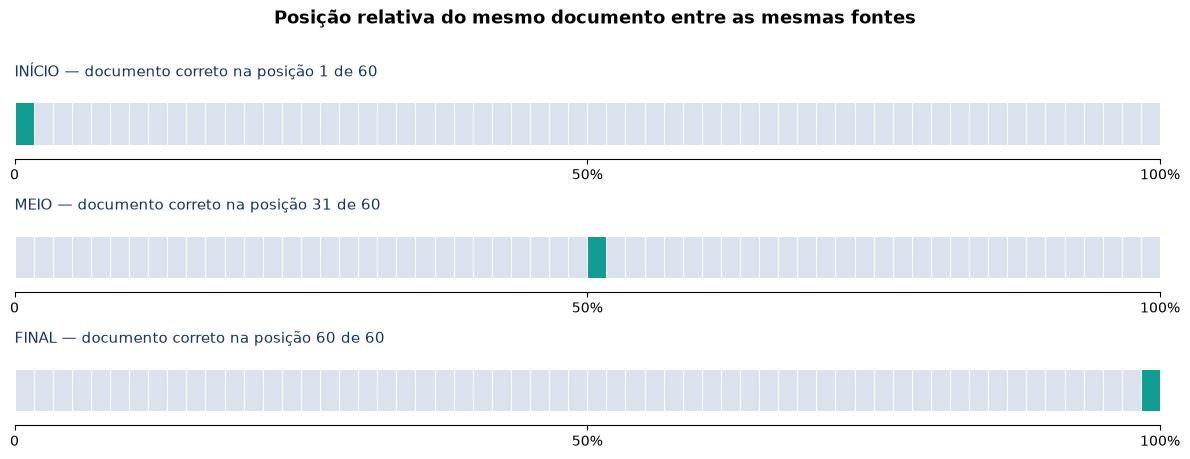

In [4]:
# Diagrama produzido a partir dos documentos REALMENTE montados neste notebook.
fig,axs=plt.subplots(3,1,figsize=(12,4.5))
for ax,pos in zip(axs,POSICOES):
    seq=arranjos[pos]
    for j,d in enumerate(seq):
        ax.barh(0,1,left=j,color='#119D91' if d['relevante'] else '#DCE2ED',height=.6,
                edgecolor='white',linewidth=.7)
    alvo_idx = next(j for j,d in enumerate(seq) if d['relevante'])
    ax.set_xlim(0,len(seq));ax.set_ylim(-.5,.55);ax.set_yticks([])
    ax.set_xticks([0,len(seq)//2,len(seq)],['0','50%','100%'])
    ax.set_title(f'{pos.upper()} — documento correto na posição {alvo_idx+1} de {len(seq)}',loc='left',fontsize=11,color='#173568')
    ax.spines[['top','right','left']].set_visible(False)
fig.suptitle('Posição relativa do mesmo documento entre as mesmas fontes',fontsize=13,fontweight='bold',y=1.01)
plt.tight_layout();plt.show()

### Verificação obrigatória — inspecione o contexto antes da chamada

Antes de confiar no experimento, confira se a preparação dos dados corresponde ao desenho experimental:

1. A fonte relevante está no início, no meio e no final, conforme a condição?
2. A **pergunta** permanece exatamente igual?
3. O **conjunto de documentos** é idêntico nas três versões, ainda que a ordem mude?
4. A resposta de referência aparece no documento correto, e não foi adicionada artificialmente às instruções?

A próxima célula fornece uma amostra do conteúdo montado para auditoria humana. **Nenhum arquivo arbitrário do seu computador é lido automaticamente.**


In [5]:
for pos in POSICOES:
    seq = arranjos[pos]
    alvo = next(d for d in seq if d['relevante'])
    print(f'{pos:6s} | doc. alvo = {alvo["id"]} | primeiro = {seq[0]["id"]} | último = {seq[-1]["id"]}')
print('\nPERGUNTA IGUAL EM TODAS AS CONDIÇÕES:\n',caso_piloto['pergunta'])
print('\nTRECHO DO DOCUMENTO CERTO (apenas para inspecionar):\n', docs_base[0]['texto'][:320])

Início | doc. alvo = OPS-227 | primeiro = OPS-227 | último = OPS-758
Meio   | doc. alvo = OPS-227 | primeiro = OPS-729 | último = OPS-758
Final  | doc. alvo = OPS-227 | primeiro = OPS-758 | último = OPS-227

PERGUNTA IGUAL EM TODAS AS CONDIÇÕES:
 Qual é o read_timeout do serviço Checkout Orion no ambiente de produção, versão v2026.4?

TRECHO DO DOCUMENTO CERTO (apenas para inspecionar):
 ID: OPS-227
Título: Runbook de configuração — Checkout Orion
Serviço: Checkout Orion
Ambiente: produção
Versão: v2026.4
Status: VIGENTE
Configuração read_timeout: 17 segundos.
Este é o valor de referência validado para a combinação acima.

Seção operacional 1: Mudanças de configuração exigem registro de versão, respons


## 6. Execute o experimento com um LLM real

**Atenção:** esta etapa pode realizar chamadas pagas à API. Para habilitá-las, configure `OPENAI_API_KEY`, escolha um modelo acessível e altere `EXECUTAR_API = True` na célula inicial. Com a chave ausente ou a execução desativada, o notebook **não inventará respostas nem métricas**.

**Configurações ilustrativas:**

- **Experimento mínimo:** 1 pergunta × 3 posições × 1 repetição = **3 chamadas**.
- **Investigação ampliada:** 3 perguntas × 3 posições × 3 repetições = **27 chamadas**.

**Cuidados de execução:**

- Cada posição gera uma requisição independente, sem histórico compartilhado com os outros testes.
- O modelo, as instruções e a configuração permanecem iguais entre as posições.
- Limites e cobrança dependem da API; o notebook não calcula preços em dinheiro.
- `max_output_tokens` também pode abranger tokens internos de raciocínio; uma saída interrompida por limite é identificada separadamente e **não deve ser tratada automaticamente como resposta factual incorreta**.
- Podem existir pequenas variações entre execuções, mesmo sem mudanças deliberadas nos parâmetros.

**Atividade:** registre os resultados das três posições. Caso todas as respostas estejam corretas, registre esse resultado normalmente: não é necessário que o modelo falhe para que o procedimento experimental seja válido.


In [6]:
import importlib.util

CHAVE_API = (os.getenv('GEMINI_API_KEY') if PROVEDOR == 'gemini'
             else os.getenv('OPENAI_API_KEY'))
TEM_CHAVE = bool(CHAVE_API)
SDK_DISPONIVEL = importlib.util.find_spec('openai') is not None
print('Provedor:', PROVEDOR, '| Chave configurada?', TEM_CHAVE,
      '| SDK openai instalado?', SDK_DISPONIVEL)
print('Execução autorizada?', EXECUTAR_API)
if EXECUTAR_API and not (TEM_CHAVE and SDK_DISPONIVEL):
    print('ATENÇÃO: faltam a API key do provedor selecionado e/ou o pacote openai.')

def criar_cliente():
    from openai import OpenAI
    if PROVEDOR == 'gemini':
        return OpenAI(api_key=CHAVE_API,
                      base_url='https://generativelanguage.googleapis.com/v1beta/openai/',
                      timeout=120.0, max_retries=1)
    return OpenAI(api_key=CHAVE_API, timeout=120.0, max_retries=1)


Provedor: gemini | Chave configurada? True | SDK openai instalado? True
Execução autorizada? True


In [7]:
def normalizar(texto):
    texto = str(texto or '').strip().lower()
    texto = ''.join(c for c in unicodedata.normalize('NFKD',texto) if not unicodedata.combining(c))
    return re.sub(r'[\s\.,;:!]+$', '', texto)

def extrair_json(texto):
    texto = (texto or '').strip()
    if texto.startswith('```'):
        texto = re.sub(r'^```(?:json)?\s*|\s*```$', '', texto, flags=re.I).strip()
    try:
        objeto = json.loads(texto)
        if isinstance(objeto, dict): return objeto
    except (ValueError,TypeError): pass
    trecho = re.search(r'\{.*?\}', texto, re.S)
    if trecho:
        try: return json.loads(trecho.group(0))
        except ValueError: pass
    return {'resposta':texto, 'fonte':None}

def avaliar_resposta(texto, caso):
    data = extrair_json(texto)
    resposta = normalizar(data.get('resposta'))
    esperado = normalizar(caso['valor'])
    # Correção estrita da referência; um score automático não substitui leitura humana.
    acerto = (resposta == esperado)
    fonte = normalizar(data.get('fonte'))
    citacao = (fonte == normalizar(caso['fonte']))
    return {'resposta_extraida':data.get('resposta'), 'fonte_extraida':data.get('fonte'),
            'acerto_exato':bool(acerto), 'fonte_correta':bool(citacao),
            'acerto_e_fonte':bool(acerto and citacao)}

# Autotestes locais do avaliador, executados sem API.
t=avaliar_resposta('{"resposta":"17 segundos","fonte":"OPS-227"}',CASOS[0])
assert t['acerto_e_fonte']
assert not avaliar_resposta('{"resposta":"10 segundos","fonte":"OPS-227"}',CASOS[0])['acerto_exato']
assert avaliar_resposta('{"resposta":"17 segundos.","fonte":"OPS-227"}',CASOS[0])['acerto_e_fonte']
print('Avaliador validado com exemplos determinísticos (NÃO são resultados de LLM).')

Avaliador validado com exemplos determinísticos (NÃO são resultados de LLM).


In [8]:
def executar_chamada(caso, documentos, client, modelo=MODELO):
    usuario = montar_entrada(caso, documentos)
    antes = time.perf_counter()

    if PROVEDOR == 'gemini':
        # Gemini aceita a biblioteca openai no endpoint Chat Completions.
        resposta = client.chat.completions.create(
            model=modelo,
            messages=[{'role': 'system', 'content': INSTRUCOES},
                      {'role': 'user', 'content': usuario}],
            max_tokens=MAX_OUTPUT_TOKENS,
        )
        escolha = resposta.choices[0]
        texto = escolha.message.content or ''
        uso = resposta.usage
        # Sem resposta completa (ex.: limite de saída) não contar como erro de recuperação.
        motivo = escolha.finish_reason
        status = 'completed' if motivo == 'stop' else 'incomplete'
        motivo_incompleto = None if status == 'completed' else motivo
        tokens_entrada = getattr(uso, 'prompt_tokens', None)
        tokens_saida = getattr(uso, 'completion_tokens', None)
    else:
        # Mantém a chamada original da OpenAI Responses API.
        argumentos = dict(
            model=modelo,
            input=[{'role': 'system', 'content': INSTRUCOES},
                   {'role': 'user', 'content': usuario}],
            max_output_tokens=MAX_OUTPUT_TOKENS,
            truncation='disabled',
            store=False,
        )
        if modelo.startswith('gpt-5'):
            argumentos['reasoning'] = {'effort': 'low'}
        resposta = client.responses.create(**argumentos)
        texto = getattr(resposta, 'output_text', '') or ''
        uso = getattr(resposta, 'usage', None)
        status = getattr(resposta, 'status', 'desconhecido')
        detalhes = getattr(resposta, 'incomplete_details', None)
        motivo_incompleto = getattr(detalhes, 'reason', None)
        tokens_entrada = getattr(uso, 'input_tokens', None)
        tokens_saida = getattr(uso, 'output_tokens', None)

    duracao = time.perf_counter() - antes
    avaliacao = avaliar_resposta(texto, caso) if status == 'completed' and texto.strip() else {
        'resposta_extraida': None, 'fonte_extraida': None,
        'acerto_exato': np.nan, 'fonte_correta': np.nan, 'acerto_e_fonte': np.nan,
    }
    return {'resposta_bruta': texto, 'segundos': round(duracao, 2),
            'tokens_entrada': tokens_entrada, 'tokens_saida': tokens_saida,
            'status': status, 'motivo_incompleto': motivo_incompleto,
            **avaliacao}

def montar_plano(casos, n_documentos, paragrafos, repeticoes):
    plano=[]
    for k,caso in enumerate(casos):
        for repeticao in range(repeticoes):
            semente = SEMENTE + repeticao*37 + k*101
            base=criar_documentos(caso,n_documentos,paragrafos,semente)
            for pos in POSICOES:
                plano.append((caso,repeticao+1,pos,ordenar_documentos(base,pos)))
    return plano

plano = montar_plano(CASOS[:QUANTOS_CASOS], N_DOCUMENTOS,
                    PARAGRAFOS_POR_DOCUMENTO, REPETICOES)
print(f'Plano pronto: {len(plano)} requisições independentes.')
print('Primeiro teste:',plano[0][0]['nome'],'/',plano[0][2])

Plano pronto: 27 requisições independentes.
Primeiro teste: Timeout em produção / Início


In [ ]:
# ESTE É O ÚNICO BLOCO QUE EXECUTA OS TESTES PRINCIPAIS NA API.
resultados=[]
if not EXECUTAR_API:
    print('MODO PREPARAÇÃO: API desabilitada. Nenhuma resposta ou métrica foi simulada.')
elif not TEM_CHAVE or not SDK_DISPONIVEL:
    print('Sem chave do provedor selecionado ou sem biblioteca openai: nenhuma chamada realizada.')
else:
    cliente = criar_cliente()
    for ix, (caso, repeticao, pos, docs) in enumerate(plano, 1):
        print(
            f'[{ix}/{len(plano)}] {caso["nome"]} | '
            f'repetição {repeticao} | {pos}',
            flush=True
        )

        try:
            r = executar_chamada(caso, docs, cliente)

            resultados.append({
                'modelo': MODELO,
                'caso': caso['nome'],
                'repeticao': repeticao,
                'posicao': pos,
                'documentos': len(docs),
                'fonte_esperada': caso['fonte'],
                'valor_esperado': caso['valor'],
                **r
            })

        except Exception as exc:
            print(
                'Falha de API nesta configuração:',
                type(exc).__name__,
                str(exc)[:240]
            )

            resultados.append({
                'modelo': MODELO,
                'caso': caso['nome'],
                'repeticao': repeticao,
                'posicao': pos,
                'documentos': len(docs),
                'erro': str(exc)[:400],
                'acerto_e_fonte': np.nan,
                'acerto_exato': np.nan,
                'fonte_correta': np.nan
            })

        finally:
            print("Aguardando 25 segundos antes da próxima chamada...")
            time.sleep(25)

resultados_df = pd.DataFrame(resultados)
if resultados_df.empty:
    print('Tabela vazia por escolha: habilite EXECUTAR_API para produzir medidas reais.')
else:
    display(resultados_df[['caso','posicao','repeticao','resposta_bruta','acerto_exato',
                           'fonte_correta','tokens_entrada','tokens_saida','segundos']].fillna('—'))

[1/27] Timeout em produção | repetição 1 | Início
Aguardando 25 segundos antes da próxima chamada...
[2/27] Timeout em produção | repetição 1 | Meio
Aguardando 25 segundos antes da próxima chamada...
[3/27] Timeout em produção | repetição 1 | Final
Aguardando 25 segundos antes da próxima chamada...
[4/27] Timeout em produção | repetição 2 | Início
Aguardando 25 segundos antes da próxima chamada...
[5/27] Timeout em produção | repetição 2 | Meio
Aguardando 25 segundos antes da próxima chamada...
[6/27] Timeout em produção | repetição 2 | Final
Aguardando 25 segundos antes da próxima chamada...
[7/27] Timeout em produção | repetição 3 | Início
Aguardando 25 segundos antes da próxima chamada...
[8/27] Timeout em produção | repetição 3 | Meio
Aguardando 25 segundos antes da próxima chamada...
[9/27] Timeout em produção | repetição 3 | Final
Aguardando 25 segundos antes da próxima chamada...
[10/27] Retenção em produção | repetição 1 | Início
Aguardando 25 segundos antes da próxima chamada.

,caso,posicao,repeticao,resposta_bruta,acerto_exato,fonte_correta,tokens_entrada,tokens_saida,segundos
0,Timeout em produção,Início,1,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38550,15,1.89
1,Timeout em produção,Meio,1,"{""resposta"":""NAO_ENCONTRADO"",""fonte"":null}",False,False,38550,15,1.98
2,Timeout em produção,Final,1,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38550,15,1.87
3,Timeout em produção,Início,2,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38518,15,1.94
4,Timeout em produção,Meio,2,"{""resposta"":""NAO_ENCONTRADO"",""fonte"":null}",False,False,38518,15,2.06
5,Timeout em produção,Final,2,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38518,15,1.90
6,Timeout em produção,Início,3,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38460,15,1.86
7,Timeout em produção,Meio,3,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38460,15,3.30
8,Timeout em produção,Final,3,"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",True,True,38460,15,1.96
9,Retenção em produção,Início,1,"{""resposta"":""43 dias"",""fonte"":""OPS-314""}",True,True,38589,15,1.94


## 7. Interprete as evidências observadas

Ao avaliar os resultados, não olhe apenas o texto final. Verifique também se a fonte citada sustenta a resposta e se o teste terminou normalmente.

**Significado das métricas:**

- **Acerto exato:** valor e unidade correspondem à referência definida para o caso, segundo um critério automático estrito.
- **Fonte correta:** o ID citado corresponde à fonte de referência. Isso **não substitui** uma análise semântica completa de fundamentação (*grounding*).
- **Acerto + fonte:** condição mais exigente que requer valor correto e identificação correta da fonte.
- **Tokens de entrada/saída:** contagens reportadas pela API nas chamadas reais.
- **Latência:** tempo total observado entre envio e conclusão da requisição, incluindo rede e serviço.

**Analise os resultados respondendo:**

1. O modelo apresentou respostas diferentes conforme a posição?
2. Houve algum acerto com citação de fonte incorreta?
3. Os tokens e a latência foram semelhantes entre as condições?
4. Existe evidência suficiente para afirmar que ocorreu um padrão de *Lost in the Middle* neste ensaio?

**Limitação:** uma pergunta com uma repetição é suficiente para observar o procedimento e levantar hipóteses, mas não para estabelecer uma taxa de acerto robusta. Considere múltiplas perguntas, repetições e análise das respostas brutas antes de generalizar.


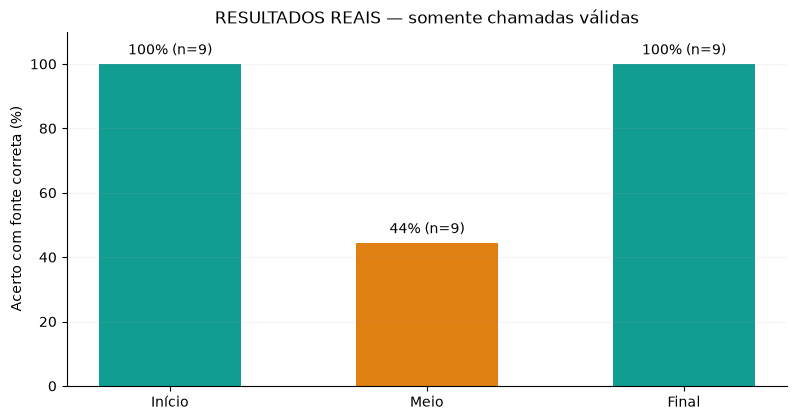

,taxa de acerto,n válido
posicao,,
Início,1.000000,9
Meio,0.444444,9
Final,1.000000,9


In [10]:
if resultados_df.empty or 'acerto_e_fonte' not in resultados_df.columns:
    print('SEM RESULTADOS REAIS: o gráfico abaixo não será inventado.')
else:
    validos=resultados_df.dropna(subset=['acerto_e_fonte']).copy()
    if validos.empty:
        print('Não houve execuções válidas para calcular o gráfico.')
    else:
        validos['acerto_e_fonte']=validos['acerto_e_fonte'].astype(float)
        ordem=['Início','Meio','Final']
        agr=validos.groupby('posicao')['acerto_e_fonte'].agg(['mean','count']).reindex(ordem)
        fig, ax=plt.subplots(figsize=(9.3,4.6))
        ax.bar(agr.index,agr['mean']*100,color=['#119D91','#E07F12','#119D91'],width=.55)
        ax.set_ylim(0,110);ax.set_ylabel('Acerto com fonte correta (%)')
        ax.set_title('RESULTADOS REAIS — somente chamadas válidas')
        for i,(_,linha) in enumerate(agr.iterrows()):
            if pd.notna(linha['mean']):
                ax.text(i,linha['mean']*100+3, f'{linha["mean"]*100:.0f}% (n={int(linha["count"])})',ha='center')
        ax.spines[['top','right']].set_visible(False)
        ax.grid(axis='y',alpha=.12)
        plt.show()
        display(agr.rename(columns={'mean':'taxa de acerto','count':'n válido'}))
        if len(validos)<9:
            print('ATENÇÃO: poucas execuções — gráfico é descritivo, não uma curva experimental generalizável.')

In [11]:
if resultados_df.empty:
    print('Nenhuma medida disponível para auditoria de tokens ou latência.')
else:
    campos=[x for x in ['caso','posicao','tokens_entrada','tokens_saida','segundos','status']
            if x in resultados_df.columns]
    display(resultados_df[campos].fillna('—'))
    print('A ordem de documentos pode alterar ligeiramente a tokenização nas fronteiras;')
    print('a lista de documentos e o total de caracteres foram mantidos constantes.')

,caso,posicao,tokens_entrada,tokens_saida,segundos,status
0,Timeout em produção,Início,38550,15,1.89,completed
1,Timeout em produção,Meio,38550,15,1.98,completed
2,Timeout em produção,Final,38550,15,1.87,completed
3,Timeout em produção,Início,38518,15,1.94,completed
4,Timeout em produção,Meio,38518,15,2.06,completed
5,Timeout em produção,Final,38518,15,1.90,completed
6,Timeout em produção,Início,38460,15,1.86,completed
7,Timeout em produção,Meio,38460,15,3.30,completed
8,Timeout em produção,Final,38460,15,1.96,completed
9,Retenção em produção,Início,38589,15,1.94,completed


A ordem de documentos pode alterar ligeiramente a tokenização nas fronteiras;
a lista de documentos e o total de caracteres foram mantidos constantes.


## 8. Testes de controle: documento isolado e evidência ausente

Antes de associar uma falha à posição no contexto longo, é útil comparar duas condições adicionais:

- **Oracle / fonte isolada:** fornecer **somente o documento correto**. Isso verifica como o modelo responde sem os demais documentos competindo por atenção.
- **Ausência da evidência:** retirar o documento correto e manter os distratores. Como o assistente é instruído a não inventar valores, a resposta de referência para essa condição é **`NAO_ENCONTRADO`**.

**Diferença em relação ao artigo original:** o controle de ausência deste notebook **mantém distratores**, enquanto a condição *closed-book* original não fornecia documentos.

**Questões para investigar:**

1. O que significaria uma resposta incorreta mesmo quando a fonte certa é enviada isoladamente?
2. O que você concluiria se o modelo fornecesse um valor específico quando a evidência foi removida?

**Execução opcional:** altere `EXECUTAR_CONTROLES = True` na célula abaixo, depois de habilitar a API. Isso faz **duas chamadas adicionais**, separadas do gráfico principal de posições.


In [12]:
EXECUTAR_CONTROLES = True  # requer EXECUTAR_API=True e credenciais
controles=[]
if EXECUTAR_CONTROLES and EXECUTAR_API and TEM_CHAVE and SDK_DISPONIVEL:
    cliente = criar_cliente()
    para_oracle=[d for d in docs_base if d['relevante']]
    para_ausencia=[d for d in docs_base if not d['relevante']]
    for nome,docs in [('Oracle (fonte isolada)',para_oracle),('Sem evidência',para_ausencia)]:
        try:
            r=executar_chamada(caso_piloto,docs,cliente)
            controles.append({'controle':nome,**r})
        except Exception as exc:
            controles.append({'controle':nome,'erro':str(exc)})
    display(pd.DataFrame(controles))
else:
    print('Controles ainda não executados. Não há respostas fictícias.')

,controle,resposta_bruta,segundos,tokens_entrada,tokens_saida,status,motivo_incompleto,resposta_extraida,fonte_extraida,acerto_exato,fonte_correta,acerto_e_fonte
0,Oracle (fonte isolada),"{""resposta"":""17 segundos"",""fonte"":""OPS-227""}",1.04,821,15,completed,None,17 segundos,OPS-227,True,True,True
1,Sem evidência,"{""resposta"":""NAO_ENCONTRADO"",""fonte"":null}",2.27,37911,15,completed,None,NAO_ENCONTRADO,NaN,False,False,False


## 9. Extensão: posição × comprimento do contexto

O estudo de *Lost in the Middle* também motiva investigar se o comportamento muda quando o número de documentos cresce.

Experimente planejar lotes com **10, 30 e 60 documentos**, sempre que o limite do modelo permitir. Para cada tamanho, execute as três posições da evidência usando o mesmo conjunto documental daquela condição.

**Cuidado metodológico:** alterar a quantidade de documentos também altera o número de distratores e a dificuldade da tarefa. Portanto, não misture o efeito do **comprimento** com o efeito da **posição** sem separar as comparações.

**Proposta de trabalho em grupos:**

- Um grupo investiga o conjunto com 10 documentos; outro, 30; e outro, 60.
- Cada grupo verifica as posições início, meio e final com repetições, se possível.
- Ao final, comparem os resultados entre posições **dentro do mesmo tamanho**, antes de discutir diferenças entre tamanhos.

A próxima célula **apenas planeja e estima o volume de texto**. Ela não faz inferência, não calcula tokens exatos e não informa custo monetário.


In [13]:
planejamento=[]
for qtde in [10,30,60]:
    pool=criar_documentos(CASOS[0],qtde,PARAGRAFOS_POR_DOCUMENTO,SEMENTE)
    texto=montar_entrada(CASOS[0],pool)
    planejamento.append({'Documentos':qtde,'Caracteres':len(texto),
                         'Tokens aproximados*':round(len(texto)/4),
                         'Chamadas c/ 3 posições e 2 repetições':6})
display(pd.DataFrame(planejamento))
print('* Proxy por caracteres, não contagem exata do tokenizador.')

,Documentos,Caracteres,Tokens aproximados*,Chamadas c/ 3 posições e 2 repetições
0,10,30685,7671,6
1,30,91494,22874,6
2,60,182723,45681,6


* Proxy por caracteres, não contagem exata do tokenizador.


## 10. Atividade de investigação — roteiro do estudante

Utilize esta sequência para organizar sua execução e registrar evidências antes de tirar conclusões.

| Etapa | Tempo de referência | Sua tarefa |
|:--|:--:|:--|
| **1. Problema** | 5 min | Leia a questão de pesquisa e formule sua hipótese sobre início, meio e final. |
| **2. Método** | 8 min | Identifique a pergunta, a fonte relevante, os distratores e o que será mantido constante. |
| **3. Auditoria** | 7 min | Execute as células locais. Confirme a equivalência das fontes e a mudança controlada de posição. |
| **4. Execução real** | 10–15 min | Caso a API esteja habilitada, realize três chamadas independentes. Não antecipe resultados. |
| **5. Análise** | 10 min | Compare acerto, fonte, tokens, latência e eventuais erros de execução. |
| **6. Discussão** | 10 min | Proponha controles, repetições e possíveis estratégias de mitigação. |

### Perguntas para discussão

1. Uma resposta incorreta com a evidência no meio comprova um problema universal do modelo? Por quê?
2. Se o modelo acertar as três posições, como interpretar o resultado diante do estudo original?
3. Uma resposta com valor correto, mas fonte citada incorretamente, pode ser considerada bem fundamentada?
4. Por que manter fixo o conjunto de documentos entre os testes de posição?
5. Que estratégias de engenharia de contexto poderiam ser investigadas em seguida?

**Entregável:** um registro curto com a hipótese, a configuração utilizada, os resultados observados, as limitações e a conclusão sustentada pelas evidências.

**Ideia a consolidar:** o limite nominal indica quanto conteúdo pode ser recebido; o uso efetivo precisa ser medido em tarefas e condições específicas.


## 11. Registre suas conclusões após a execução

Preencha as informações abaixo **somente com o que foi efetivamente observado**. Se não executou as chamadas reais, indique “não medido”.

- **Modelo e versão:** _____________________
- **Número de documentos e tamanho aproximado do contexto:** _____________________
- **Resultado com evidência no início:** _____________________
- **Resultado com evidência no meio:** _____________________
- **Resultado com evidência no final:** _____________________
- **Identificador de fonte citado corretamente?** _____________________
- **Tokens e latência:** _____________________
- **Erros de API ou variáveis não controladas:** _____________________
- **Conclusão apoiada pelos resultados:** _____________________
- **Próximo teste recomendado:** _____________________

**Não ajuste a interpretação para reproduzir o padrão em U do artigo.** Um resultado sem diferenças entre as posições também é uma observação válida nas condições estudadas.

### Referências

- Liu, N. F. et al. (2024). [*Lost in the Middle: How Language Models Use Long Contexts*](https://aclanthology.org/2024.tacl-1.9/). *Transactions of the Association for Computational Linguistics*, 12, 157–173. DOI: 10.1162/tacl_a_00638.
- [Repositório original dos autores](https://github.com/nelson-liu/lost-in-the-middle) — código, experimentos de QA multidocumental e recuperação chave–valor.
- [OpenAI Responses API — referência técnica](https://developers.openai.com/api/reference/python/resources/responses/methods/create).

**Nota científica:** este é um laboratório educacional baseado na metodologia da literatura, e não uma reprodução dos resultados empíricos publicados.
